| Phần            | Nội dung                                         |
| --------------- | ------------------------------------------------ |
| 2.2.1           | Cơ cấu nguồn và độ bao phủ dữ liệu               |
| 2.2.2           | Top 15 kỹ năng                                   |
| 2.2.3           | Lương theo cấp bậc                               |
| 2.2.4           | So sánh các khu vực                              |
| 2.2.5 — Mở rộng | Kỹ năng theo cấp bậc trong cùng nhóm nghề        |
| 2.2.6 — Mở rộng | Ngoại ngữ và quyền lợi theo nhóm nghề            |
| 2.2.7 — Mở rộng | Đối chiếu kết quả theo tin, tên công ty và nguồn |


# Bước 2.2 — EDA


## 2.2.1 — Đọc dữ liệu, xem cơ cấu và độ bao phủ


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = Path("data/processed/clean_data_processed.csv")

df_all = pd.read_csv(data_path)

# Chỉ khôi phục các danh sách cần dùng ở những phần đầu
for column in ["skills", "cities_clean"]:
    df_all[column] = df_all[column].map(json.loads)

df = df_all.loc[df_all["scope_status"].eq("included_provisional")].copy()

assert df["job_uid"].notna().all()
assert df["job_uid"].is_unique

for column in ["has_jd_clean", "salary_eda_eligible", "salary_eda_conservative"]:
    assert pd.api.types.is_bool_dtype(df[column])

plt.rcParams.update(
    {"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False}
)

print(f"Tổng tin đại diện: {len(df_all):,}")
print(f"Tin IT dùng sơ bộ: {len(df):,}")

Tổng tin đại diện: 3,135
Tin IT dùng sơ bộ: 2,869


In [ ]:
# Kiểm tra mỗi nguồn đóng góp bao nhiêu tin và cung cấp được những thông tin nào:
source_summary = df.groupby("source").agg(
    n_jobs=("job_uid", "size"),
    n_jd=("has_jd_clean", "sum"),
    n_salary=("salary_eda_eligible", "sum"),
    n_workmode=("work_mode_clean", lambda s: s.ne("Unknown").sum()),
)

source_summary["sample_share_pct"] = source_summary["n_jobs"] / len(df) * 100

for field in ["jd", "salary", "workmode"]:
    source_summary[f"{field}_pct"] = (
        source_summary[f"n_{field}"] / source_summary["n_jobs"] * 100
    )

display(source_summary.round(2))

,n_jobs,n_jd,n_salary,n_workmode,sample_share_pct,jd_pct,salary_pct,workmode_pct
source,,,,,,,,
itviec,551,530,118,551,19.21,96.19,21.42,100.00
linkedin,637,637,5,129,22.20,100.00,0.78,20.25
topcv,1143,1138,468,37,39.84,99.56,40.94,3.24
topdev,61,61,9,9,2.13,100.00,14.75,14.75
vietnamworks,477,477,88,19,16.63,100.00,18.45,3.98


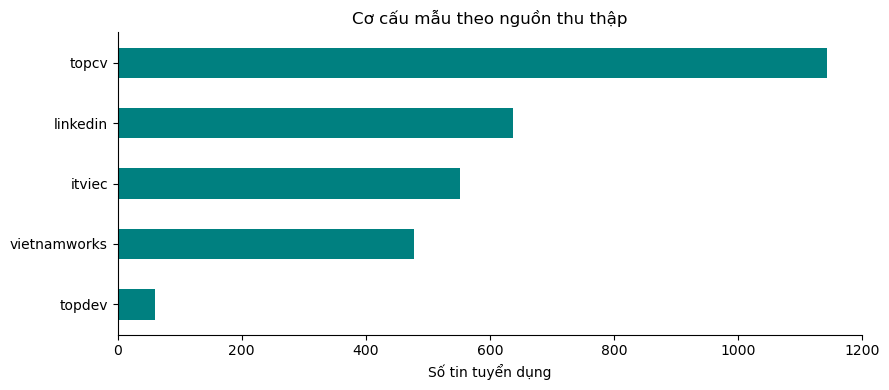

In [3]:
ax = source_summary["n_jobs"].sort_values().plot.barh(color="teal")

ax.set_title("Cơ cấu mẫu theo nguồn thu thập")
ax.set_xlabel("Số tin tuyển dụng")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Vì sao xem phần này trước? Nguồn dữ liệu có thể ảnh hưởng đến kết luận. Chẳng hạn, trong file hiện tại, tỷ lệ đủ điều kiện phân tích lương là khoảng 40,94% ở TopCV, nhưng chỉ 0,78% ở LinkedIn.

Do đó, thống kê lương không phản ánh đồng đều tất cả nguồn.


## 2.2.2 — Top 15 kỹ năng được ghi nhận nhiều nhất


In [4]:
from sklearn.preprocessing import MultiLabelBinarizer

df_skills = df.loc[df["has_jd_clean"]].copy()

mlb = MultiLabelBinarizer()

skill_matrix = pd.DataFrame(
    mlb.fit_transform(df_skills["skills"]),
    index=pd.Index(df_skills["job_uid"], name="job_uid"),
    columns=mlb.classes_,
)

assert np.array_equal(
    skill_matrix.sum(axis=1).to_numpy(), df_skills["n_skills"].to_numpy()
)

skill_demand = (
    skill_matrix.sum().sort_values(ascending=False).rename("n_jobs").to_frame()
)

skill_demand["mention_pct"] = skill_demand["n_jobs"] / len(df_skills) * 100

display(skill_demand.head(15).round(2))

,n_jobs,mention_pct
Python,912,32.08
SQL,802,28.21
CI/CD,711,25.01
Docker,538,18.92
AWS,530,18.64
Agile,519,18.26
Java,512,18.01
Linux,496,17.45
Git,494,17.38
DevOps,468,16.46


Mẫu số là toàn bộ tin có JD, gồm cả giỏ kỹ năng rỗng. Nếu chỉ dùng những tin trích được kỹ năng, tỷ lệ sẽ bị tăng lên.


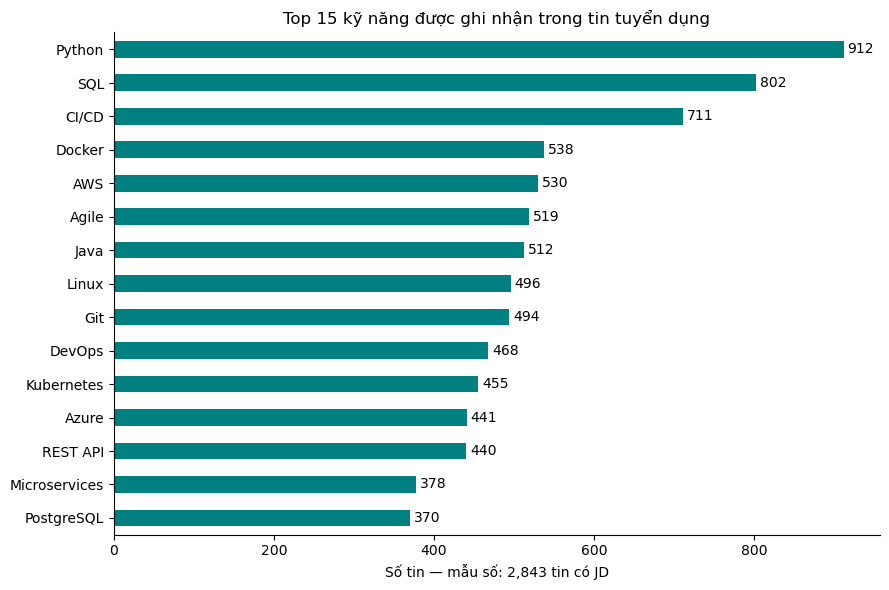

In [5]:
top15 = skill_demand.head(15).iloc[::-1]

ax = top15["n_jobs"].plot.barh(color="teal", figsize=(9, 6))

for position, value in enumerate(top15["n_jobs"]):
    ax.text(value + 5, position, str(value), va="center")

ax.set_title("Top 15 kỹ năng được ghi nhận trong tin tuyển dụng")
ax.set_xlabel(f"Số tin — mẫu số: {len(df_skills):,} tin có JD")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Diễn giải: Trong tập tin có JD, kỹ năng X được ghi nhận trong N tin, chiếm P%.

Đây là tần suất trong dữ liệu thu thập, chưa phải số người cần tuyển hoặc mức độ bắt buộc của kỹ năng.


## 2.2.3 — Phân bố lương theo cấp bậc


In [7]:
df_salary = df.loc[df["salary_eda_eligible"]].copy()

df_salary["salary_million"] = df_salary["Luong_TB"] / 1_000_000

level_order = [
    "Intern",
    "Fresher",
    "Junior",
    "Middle",
    "Senior",
    "Lead",
    "Multi-level",
    "Unknown",
]

salary_by_level = df_salary.groupby("seniority_clean")["salary_million"].agg(
    n_salary="size",
    median_million="median",
    q1_million=lambda s: s.quantile(0.25),
    q3_million=lambda s: s.quantile(0.75),
)

salary_by_level["n_jobs"] = df.groupby("seniority_clean").size()

salary_by_level["eligible_salary_pct"] = (
    salary_by_level["n_salary"] / salary_by_level["n_jobs"] * 100
)

display(salary_by_level.reindex(level_order).round(2))

,n_salary,median_million,q1_million,q3_million,n_jobs,eligible_salary_pct
seniority_clean,,,,,,
Intern,35,4.00,2.88,6.50,92,38.04
Fresher,71,13.50,11.25,17.75,130,54.62
Junior,254,18.00,14.00,22.50,782,32.48
Middle,116,30.00,22.38,35.62,504,23.02
Senior,67,37.50,28.75,49.00,676,9.91
Lead,97,30.50,24.50,45.00,358,27.09
Multi-level,14,21.50,17.81,32.97,108,12.96
Unknown,34,32.29,24.99,35.00,219,15.53


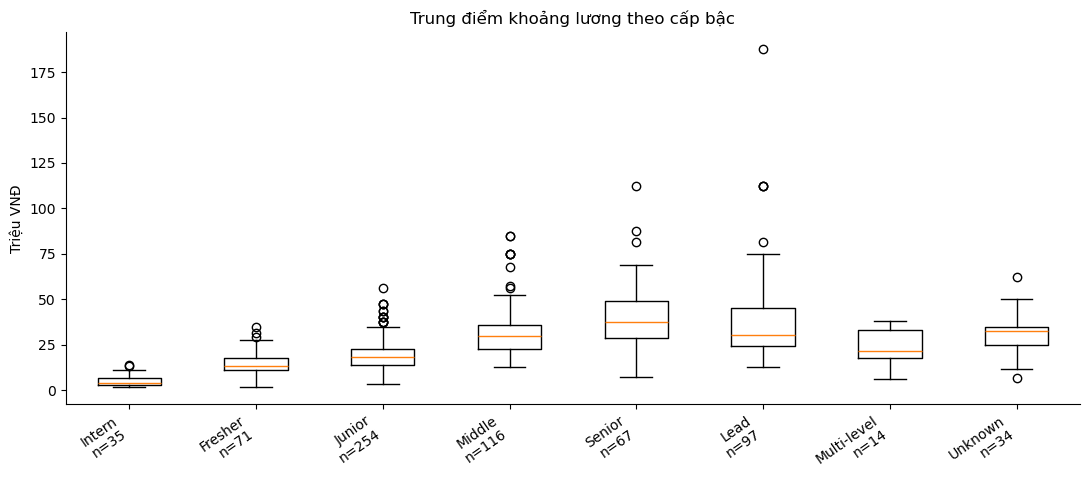

In [8]:
plot_levels = [
    level for level in level_order if df_salary["seniority_clean"].eq(level).any()
]

salary_groups = [
    df_salary.loc[df_salary["seniority_clean"].eq(level), "salary_million"]
    for level in plot_levels
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.boxplot(salary_groups, showfliers=True)

ax.set_xticks(range(1, len(plot_levels) + 1))
ax.set_xticklabels(
    [f"{level}\nn={len(values)}" for level, values in zip(plot_levels, salary_groups)],
    rotation=35,
    ha="right",
)

ax.set_title("Trung điểm khoảng lương theo cấp bậc")
ax.set_ylabel("Triệu VNĐ")

plt.tight_layout()
plt.show()

Dùng median và tứ phân vị để mô tả phân bố; vẫn giữ các điểm ngoại lệ để kiểm tra.


In [9]:
salary_conservative = df_salary.loc[df_salary["salary_eda_conservative"]]

display(
    pd.DataFrame(
        {
            "Toàn bộ tập lương hợp lệ": df_salary["salary_million"].describe(),
            "Không giả định chu kỳ": salary_conservative["salary_million"].describe(),
        }
    )
    .loc[["count", "25%", "50%", "75%"]]
    .round(2)
)

,Toàn bộ tập lương hợp lệ,Không giả định chu kỳ
count,688.0,321.00
25%,15.0,18.50
50%,22.0,28.12
75%,32.5,38.00


Diễn giải: `Luong_TB` là trung điểm khoảng chào tuyển. Không gọi đó là lương thực nhận hoặc thu nhập trung bình của người lao động.


## 2.2.4 — So sánh Hà Nội, TP.HCM và Đà Nẵng


In [10]:
geo = df[["job_uid", "cities_clean", "Luong_TB", "salary_eda_eligible"]].copy()

# Giữ cả nhóm chưa biết địa điểm
geo["cities_clean"] = geo["cities_clean"].map(lambda xs: xs or ["Unknown"])

# Một tin tuyển k nơi được phân bổ trọng số 1/k
geo["weight"] = 1 / geo["cities_clean"].str.len()

geo = geo.explode("cities_clean")

geo["salary_million"] = geo["Luong_TB"].where(geo["salary_eda_eligible"]) / 1_000_000

geo_summary = geo.groupby("cities_clean").agg(
    n_jobs=("job_uid", "nunique"),
    fractional_jobs=("weight", "sum"),
    n_salary=("salary_million", "count"),
    median_salary_million=("salary_million", "median"),
)

assert np.isclose(geo_summary["fractional_jobs"].sum(), len(df))

display(geo_summary.round(2))

,n_jobs,fractional_jobs,n_salary,median_salary_million
cities_clean,,,,
Hà Nội,1239,1207.0,407,22.50
Khác,167,167.0,57,16.00
TP.HCM,1474,1439.0,231,21.00
Unknown,14,14.0,4,31.25
Đà Nẵng,49,42.0,10,41.25


Hai cách đếm:

- n_jobs: tin được tính tại mỗi nơi có tuyển; tổng có thể vượt số tin riêng biệt.
- fractional_jobs: chia đều cho các nơi; tổng bằng số tin riêng biệt.


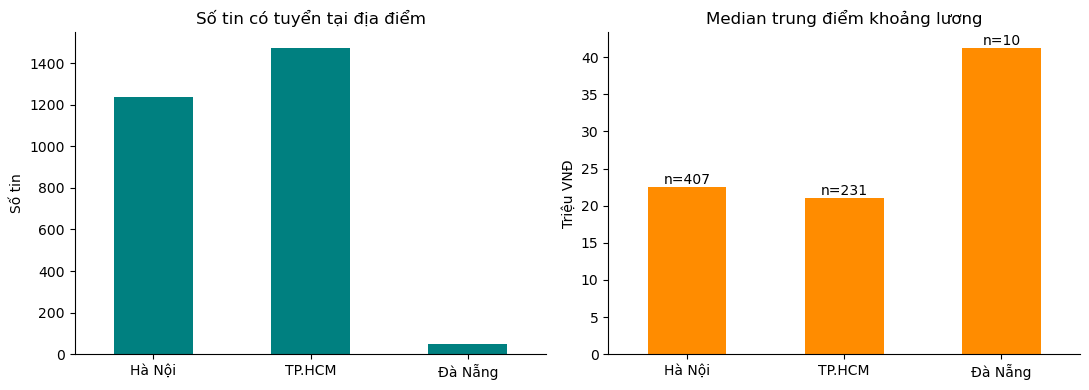

In [11]:
focus_cities = ["Hà Nội", "TP.HCM", "Đà Nẵng"]
focus_geo = geo_summary.reindex(focus_cities)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

focus_geo["n_jobs"].plot.bar(ax=axes[0], color="teal", rot=0)
axes[0].set_title("Số tin có tuyển tại địa điểm")
axes[0].set_xlabel("")
axes[0].set_ylabel("Số tin")

focus_geo["median_salary_million"].plot.bar(ax=axes[1], color="darkorange", rot=0)
axes[1].set_title("Median trung điểm khoảng lương")
axes[1].set_xlabel("")
axes[1].set_ylabel("Triệu VNĐ")

for position, row in enumerate(focus_geo.itertuples()):
    axes[1].text(
        position,
        row.median_salary_million,
        f"n={row.n_salary}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

Hiện tại, Đà Nẵng chỉ có 10 tin đủ điều kiện phân tích lương. Median cao hơn chưa đủ để kết luận khu vực này trả lương cao hơn, vì cơ cấu nghề và cấp bậc có thể khác.


## 2.2.5 — Mở rộng: kỹ năng theo cấp bậc trong cùng nhóm nghề


In [12]:
role_map = {
    "software": "Phần mềm/Web",
    "backend": "Phần mềm/Web",
    "frontend": "Phần mềm/Web",
    "fullstack": "Phần mềm/Web",
    "data_ai": "Dữ liệu/AI",
    "devops_cloud": "Cloud/DevOps",
    "system_network": "Hệ thống/Mạng",
    "qa_test": "Kiểm thử",
    "security": "Bảo mật",
    "mobile": "Mobile",
    "embedded": "Embedded",
    "pm_po": "Sản phẩm/Dự án",
    "it_general": "IT tổng quát",
}

df["job_family"] = df["title_role"].map(role_map).fillna("Chưa rõ")

display(df["job_family"].value_counts().to_frame("n_jobs"))

,n_jobs
job_family,
Phần mềm/Web,901
IT tổng quát,496
Dữ liệu/AI,364
Chưa rõ,295
Cloud/DevOps,197
Hệ thống/Mạng,153
Kiểm thử,152
Bảo mật,93
Mobile,87


Bắt đầu bằng nhóm Phần mềm/Web vì có đủ mẫu ở các cấp bậc:


In [13]:
# Ghép thông tin vào đúng các mã tin trong ma trận
meta = df.set_index("job_uid").loc[skill_matrix.index]

family = "Phần mềm/Web"

family_ids = meta.index[meta["job_family"].eq(family)]

level_counts = meta.loc[family_ids, "seniority_clean"].value_counts()

display(level_counts.to_frame("n_jobs"))

skill_rates = (
    skill_matrix.loc[family_ids].groupby(meta.loc[family_ids, "seniority_clean"]).mean()
    * 100
)

selected_levels = [
    level
    for level in ["Intern", "Fresher", "Junior", "Middle", "Senior", "Lead"]
    if level_counts.get(level, 0) >= 20
]

assert selected_levels, "Chưa có cấp bậc đủ 20 tin để so sánh."

selected_skills = skill_matrix.loc[family_ids].sum().nlargest(12).index

heatmap_data = skill_rates.loc[selected_levels, selected_skills]

,n_jobs
seniority_clean,
Senior,216
Junior,204
Middle,148
Lead,122
Unknown,70
Multi-level,53
Fresher,44
Intern,33


Ngưỡng 20 tin là quy ước thực hành để hạn chế nhóm quá nhỏ, không bảo đảm kết quả đã chắc chắn.


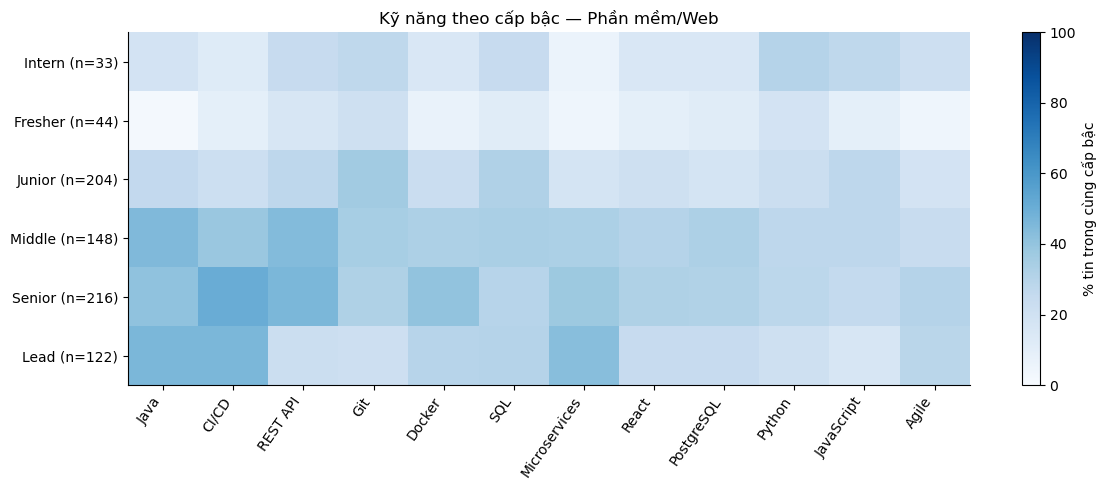

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))

image = ax.imshow(heatmap_data, aspect="auto", cmap="Blues", vmin=0, vmax=100)

ax.set_xticks(range(len(selected_skills)))
ax.set_xticklabels(selected_skills, rotation=55, ha="right")

ax.set_yticks(range(len(selected_levels)))
ax.set_yticklabels([f"{level} (n={level_counts[level]})" for level in selected_levels])

fig.colorbar(image, ax=ax, label="% tin trong cùng cấp bậc")
ax.set_title(f"Kỹ năng theo cấp bậc — {family}")

plt.tight_layout()
plt.show()

Tìm:

- Kỹ năng xuất hiện ở nhiều cấp bậc.
- Kỹ năng nổi bật hơn trong nhóm người mới vào nghề.
- Khác biệt cần kiểm tra sâu bằng luật kết hợp.


Không coi đây là lộ trình thăng tiến đã được chứng minh. Ta đang so sánh các tin khác nhau; nhiều nhãn cấp bậc còn được suy từ số năm. Có thể đối chiếu nguồn nhãn bằng:


In [15]:
display(
    pd.crosstab(
        meta.loc[family_ids, "seniority_clean"], meta.loc[family_ids, "seniority_basis"]
    )
)

seniority_basis,Unknown,level_field,title,title_intern,title_multiple_levels,years
seniority_clean,,,,,,
Fresher,0,1,8,0,0,35
Intern,0,0,0,33,0,0
Junior,0,0,16,0,0,188
Lead,0,2,120,0,0,0
Middle,0,0,18,0,0,130
Multi-level,0,0,0,0,53,0
Senior,0,1,170,0,0,45
Unknown,70,0,0,0,0,0


## 2.2.6 — Mở rộng: ngoại ngữ và quyền lợi theo nhóm nghề


In [ ]:
df["languages_clean"] = df["languages"].dropna().map(json.loads)

df["benefits_clean"] = df["benefits"].dropna().map(json.loads)


# Hai phân tích có cùng cách tính nên dùng một hàm ngắn
def mention_rates(data, list_column, group_column):
    known = data.loc[data[list_column].notna(), [group_column, list_column]].copy()

    # Mỗi nhãn chỉ được tính một lần trong một tin
    known[list_column] = known[list_column].map(lambda xs: sorted(set(xs)))

    long = known.explode(list_column).dropna(subset=[list_column])

    counts = pd.crosstab(long[group_column], long[list_column])

    sample_sizes = known.groupby(group_column).size()

    rates = (
        counts.reindex(sample_sizes.index, fill_value=0).div(sample_sizes, axis=0) * 100
    )

    return rates, sample_sizes


language_rates, language_n = mention_rates(df, "languages_clean", "job_family")

language_rates.insert(0, "n_list_available", language_n)

display(language_rates.round(1))

languages_clean,n_list_available,Chinese,English,Japanese,Korean
job_family,,,,,
Bảo mật,93,2.2,41.9,2.2,3.2
Chưa rõ,293,3.1,54.3,5.5,0.7
Cloud/DevOps,196,0.0,54.6,1.5,2.0
Dữ liệu/AI,363,0.0,47.1,1.4,0.8
Embedded,47,0.0,57.4,10.6,2.1
Hệ thống/Mạng,151,2.0,52.3,2.0,2.0
IT tổng quát,492,4.5,57.5,4.7,2.8
Kiểm thử,148,0.7,48.6,3.4,2.0
Mobile,86,0.0,41.9,3.5,1.2


In [ ]:
# Tính tỷ lệ đề cập các quyền lợi phổ biến:
benefit_rates, benefit_n = mention_rates(df, "benefits_clean", "job_family")

top_benefits = df["benefits_clean"].explode().value_counts().head(6).index

benefit_profile = benefit_rates.loc[:, top_benefits].copy()
benefit_profile.insert(0, "n_list_available", benefit_n)

display(benefit_profile.round(1))

benefits_clean,n_list_available,Thưởng (KPI/dự án/lễ tết),Du lịch / team building,Đào tạo / chứng chỉ,BHXH / chế độ theo luật,Lương tháng 13,Nghỉ phép có lương
job_family,,,,,,,
Bảo mật,86,74.4,52.3,65.1,50.0,44.2,45.3
Chưa rõ,225,80.4,56.4,53.8,48.0,42.7,35.6
Cloud/DevOps,142,78.2,58.5,57.7,50.7,47.2,45.8
Dữ liệu/AI,277,76.2,54.9,52.3,48.7,43.0,45.1
Embedded,28,82.1,64.3,57.1,46.4,53.6,35.7
Hệ thống/Mạng,150,82.7,54.7,61.3,61.3,40.0,38.0
IT tổng quát,451,76.9,48.8,51.9,51.4,40.4,37.3
Kiểm thử,133,75.9,63.9,45.9,63.2,43.6,47.4
Mobile,60,86.7,71.7,51.7,61.7,46.7,55.0


`n_list_available` là số tin có dữ liệu danh sách để làm mẫu số. Danh sách rỗng vẫn được giữ trong mẫu số; ô thiếu thì không.

Các tỷ lệ này là tỷ lệ đề cập theo kết quả trích xuất hiện có. Chưa được tự diễn giải thành yêu cầu ngoại ngữ bắt buộc hoặc quyền lợi thực tế được bảo đảm. Cần đối chiếu ngữ cảnh JD trên mẫu tin.


## 2.2.7 — Mở rộng: kết quả có phụ thuộc cách đếm và nguồn không?


In [18]:
# Chuẩn hóa cơ bản tên công ty
df["company_key"] = (
    df["company"]
    .astype("string")
    .str.normalize("NFC")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.casefold()
    .replace("", pd.NA)
)

meta = df.set_index("job_uid").loc[skill_matrix.index]

# So sánh số tin với số tên công ty đề cập kỹ năng
known_company = meta["company_key"].notna()

company_matrix = (
    skill_matrix.loc[known_company]
    .groupby(meta.loc[known_company, "company_key"])
    .max()
)

skill_comparison = pd.DataFrame(
    {"n_jobs": skill_matrix.sum(), "n_company_names": company_matrix.sum()}
)

skill_comparison["rank_jobs"] = skill_comparison["n_jobs"].rank(
    method="min", ascending=False
)

skill_comparison["rank_company_names"] = skill_comparison["n_company_names"].rank(
    method="min", ascending=False
)

display(skill_comparison.sort_values("n_jobs", ascending=False).head(15))

,n_jobs,n_company_names,rank_jobs,rank_company_names
Python,912,552,1.0,1.0
SQL,802,538,2.0,2.0
CI/CD,711,441,3.0,3.0
Docker,538,355,4.0,4.0
AWS,530,327,5.0,8.0
Agile,519,330,6.0,7.0
Java,512,306,7.0,10.0
Linux,496,331,8.0,6.0
Git,494,355,9.0,4.0
DevOps,468,316,10.0,9.0


`max()` nghĩa là một tên công ty chỉ đóng góp tối đa một lần cho mỗi kỹ năng, dù đăng nhiều tin có kỹ năng đó.

Nếu thứ hạng thay đổi nhiều, ta có bằng chứng rằng kết luận phụ thuộc vào đơn vị đếm. Cách đếm theo tin và theo công ty trả lời hai câu hỏi khác nhau, không có cách nào mặc nhiên đúng hơn.


In [19]:
# Đối chiếu tỷ lệ theo nguồn
source_skill_rates = skill_matrix.groupby(meta["source"]).mean() * 100

top_skill_names = skill_demand.head(15).index

display(source_skill_rates.loc[:, top_skill_names].T.round(1))

source,itviec,linkedin,topcv,topdev,vietnamworks
Python,36.4,46.9,22.5,27.9,30.8
SQL,30.8,23.7,27.0,32.8,33.8
CI/CD,33.4,43.2,15.5,21.3,14.7
Docker,24.7,25.7,14.9,19.7,12.8
AWS,26.2,29.5,12.2,23.0,10.5
Agile,24.7,24.8,14.2,13.1,12.6
Java,22.1,28.9,12.0,11.5,14.0
Linux,15.5,21.8,16.0,16.4,17.4
Git,18.3,24.8,14.1,14.8,14.5
DevOps,23.2,24.0,11.3,11.5,11.7


Mẫu số ở đây là số tin có JD của từng nguồn. Khác biệt có thể đến từ cơ cấu nhóm nghề, cấp bậc và cách thu thập; chưa thể quy hết cho khác biệt thị trường.

Khi viết nhận xét cho 2.2, mỗi kết luận nên có ba phần: điều quan sát được, số mẫu/mẫu số và giới hạn diễn giải. Các bảng tổng hợp trên nằm trong notebook; chưa cần lưu thêm CSV. Các cột mới được tạo đúng lúc cần và có thể giữ lại khi chuẩn bị sang 2.3.
